# Spotify Genre Classifier: training the model for the app

In this notebook I train the model that my app uses. The app has a backend with a REST API (Flask) and a frontend (React), and they are in the backend and frontend folders next to this notebook.

The notebook does five things:

1. Loads and cleans the data, in the same way as in my previous assignment.
2. Trains an XGBoost model with the best settings from my previous assignment, but without popularity, so the model only uses how a song sounds.
3. Tunes a threshold for every genre.
4. Tests which features are most important.
5. Saves the model and all the results to the models folder, so the backend can use them without training again.

I use the same cleaning, the same six genres and the same split as in my previous assignment, so the results can be compared.

In [1]:
import numpy as np
import pandas as pd

from sklearn.preprocessing import LabelEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

from xgboost import XGBClassifier

from sklearn.model_selection import StratifiedKFold, cross_val_predict


import pickle


from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score

import matplotlib.pyplot as plt

from sklearn.inspection import permutation_importance

import json
import os

# One random_state for the whole notebook, so every run gives the same split and results
random_state = 42

## Loading the data

The dataset is the Spotify Tracks dataset from Kaggle, the same file as in my previous assignment.

Sources:

- https://www.kaggle.com/datasets/maharshipandya/-spotify-tracks-dataset
- https://pandas.pydata.org/docs/reference/api/pandas.read_csv.html

In [2]:
df = pd.read_csv('../dataset/spotify.csv')

# Unnamed: 0 is only the row number, so it has no information
df = df.drop(columns='Unnamed: 0')

print(f"Rows: {len(df)}, columns: {df.shape[1]}")

Rows: 114000, columns: 20


### Interpretation

The full dataset has 114,000 songs and 20 columns after dropping Unnamed: 0, the same as in my previous assignment.

## Cleaning

I don't repeat the whole EDA here, since it is in my previous assignment. These are the cleaning steps I decided on there, in the same order:

1. Keep only the six genres: classical, country, heavy-metal, hip-hop, jazz and techno. They sound very different and share almost no songs.
2. Remove exact duplicate rows.
3. Remove songs that are listed under two of the six genres, since I can't know which genre is the right one.
4. Remove re-released copies: the same recording released again on another album, with a new track_id but exactly the same audio values. If I kept them, a copy could end up in both the training and the test data, which is data leakage.
5. Remove songs with a tempo of 0, where Spotify couldn't measure the tempo.

Sources:

- https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.drop_duplicates.html
- https://scikit-learn.org/stable/common_pitfalls.html

In [3]:
genres = ['classical', 'country', 'heavy-metal', 'hip-hop', 'jazz', 'techno']

# The columns that describe the recording itself. Used to find re-released copies.
audio_cols = ['duration_ms', 'danceability', 'energy', 'key', 'loudness', 'mode', 'speechiness',
              'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo', 'time_signature']

#  Keep only the six genres
df = df[df['track_genre'].isin(genres)]

#  Remove exact duplicate rows
df = df.drop_duplicates()

#  Remove songs that are listed under more than one genre
genres_per_song = df.groupby('track_id')['track_genre'].nunique()
songs_in_two_genres = genres_per_song[genres_per_song > 1].index
df = df[~df['track_id'].isin(songs_in_two_genres)]

#  Remove re-released copies, keep one copy of every recording
df = df.drop_duplicates(subset=audio_cols)

#  Remove songs where Spotify couldn't measure a tempo
df = df[df['tempo'] != 0]

print(f"Songs left: {len(df)}")
print(df['track_genre'].value_counts())

Songs left: 4650
track_genre
heavy-metal    991
techno         974
classical      805
hip-hop        747
country        633
jazz           500
Name: count, dtype: int64


### Interpretation

After the cleaning, 4,650 songs are left, exactly the same as in my previous assignment. The genres are not balanced: heavy-metal has 991 songs and techno 974, while jazz only has 500 and country 633. This is mostly because of the re-released copies I removed. In my previous assignment I found that jazz and country had by far the most of them. Because of this I use the macro average for F1, so every genre counts the same, and it is also a reason why the genres might need different thresholds later.

## Song names and features

The app needs the song names, so a user can search for a song and get a prediction. I keep the names in a separate table, song_info, and then drop the columns that are names or IDs from the features, so the model only learns from how a song sounds. I also leave popularity out of the features, which I explain under "Training the model".

explicit is True/False, so I turn it into 1/0.

In [4]:
# Names for the app, with the same index as the data
song_info = df[['track_id', 'track_name', 'artists', 'album_name']].copy()

# Drop names and IDs, they don't describe how a song sounds
df = df.drop(columns=['track_id', 'artists', 'album_name', 'track_name'])

df['explicit'] = df['explicit'].astype(int)

# popularity is left out on purpose: it says how many people listen to a song, not how it sounds
features = df.drop(columns=['track_genre', 'popularity'])
print(f"Features ({features.shape[1]}): {list(features.columns)}")

Features (14): ['duration_ms', 'explicit', 'danceability', 'energy', 'key', 'loudness', 'mode', 'speechiness', 'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo', 'time_signature']


### Interpretation

14 features are left, all about the song itself, like energy, tempo and acousticness. Popularity is left out on purpose. The genre is the label, and the names are saved in song_info for the app.

## Train/test split

The model learns from the training set, and the test set is only used at the end to see how well it does on songs it has never seen. I split 80/20 for every genre separately, so each genre has the same share in both sets, exactly like last time.

The genres are turned into the numbers 0 to 5, because XGBoost needs numbers as labels.

Sources:

- https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.LabelEncoder.html
- https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.sample.html

In [5]:
# Turn the genre names into the numbers 0 to 5
label_encoder = LabelEncoder()
targets = pd.Series(label_encoder.fit_transform(df['track_genre']), index=df.index)


for number, genre in enumerate(label_encoder.classes_):
    print(f"{number} = {genre}")


# 80% of every genre for training, the rest for testing
train_indices = df.groupby('track_genre').sample(frac=0.8, random_state=random_state).index
test_indices = df.drop(train_indices).index

# Shuffle the training set once, so the rows are not sorted by genre
train_features = features.loc[train_indices].sample(frac=1, random_state=random_state)
train_targets = targets.loc[train_features.index]

test_features = features.loc[test_indices]
test_targets = targets.loc[test_indices]

print(f"\nTraining songs: {len(train_features)}, test songs: {len(test_features)}")

0 = classical
1 = country
2 = heavy-metal
3 = hip-hop
4 = jazz
5 = techno

Training songs: 3720, test songs: 930


### Interpretation

The genres get the numbers 0 to 5 in alphabetical order, from classical (0) to techno (5). The split gives 3,720 training songs and 930 test songs, the same as last time, so the model I train below can be compared directly with my previous results.

## Training the model

I don't run the whole search again here. In my previous assignment I compared ten models, tuned XGBoost with RandomizedSearchCV over 100 combinations, and chose it as my final model. Here I train it again with the best settings from that search, with one change: popularity is not in the features any more. So the only difference from my final model is popularity.

Why I remove popularity: in my previous assignment popularity was the most important feature, but it says how many people listen to a song, not how it sounds. Jazz, country and classical have many songs with a popularity of 0, so the model partly used popularity to guess these genres. In an app, that means a song from a small, unknown artist could be pushed towards jazz, country or classical just because few people listen to it. That is unfair, and it doesn't fit the goal of recognising a genre from its sound. In my previous assignment I already tested XGBoost without popularity, and the macro F1 on the test set dropped from 0.863 to 0.797, so I expect a lower score here too.

The rest of the preprocessing is the same as last time: key and time_signature are one-hot encoded, and the other numeric features are scaled. Scaling doesn't change a tree model, since it only changes the numbers and not the order of the songs, but I keep it so the pipeline is the same as last time.

Sources:

- https://xgboost.readthedocs.io/en/stable/python/sklearn_estimator.html
- https://scikit-learn.org/stable/modules/generated/sklearn.compose.ColumnTransformer.html
- https://scikit-learn.org/stable/modules/generated/sklearn.pipeline.Pipeline.html

In [6]:
numeric_features = ['duration_ms', 'danceability', 'energy', 'loudness', 'speechiness',
                    'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo']
categorical_features = ['key', 'time_signature']
binary_features = ['explicit', 'mode']

preprocessor = ColumnTransformer([
    ('numeric', StandardScaler(), numeric_features),
    ('categorical', OneHotEncoder(handle_unknown='ignore'), categorical_features),
    ('binary', 'passthrough', binary_features)
])

In [7]:


# The best settings from the RandomizedSearchCV in my previous assignment
model = Pipeline([
    ('preprocess', preprocessor),
    ('estimator', XGBClassifier(n_estimators=200, max_depth=8, learning_rate=0.05,
                                subsample=0.7, colsample_bytree=0.6, min_child_weight=3,
                                reg_lambda=2, random_state=random_state, n_jobs=1))
])

model.fit(train_features, train_targets)

test_pred = model.predict(test_features)
print(f"Accuracy: {accuracy_score(test_targets, test_pred):.3f}")
print(f"Macro F1: {f1_score(test_targets, test_pred, average='macro'):.3f}")

Accuracy: 0.817
Macro F1: 0.797


### Interpretation

The model gets an accuracy of 0.817 and a macro F1 of 0.797 on the test set. That is exactly the same macro F1 as XGBoost without popularity in my previous assignment (0.797), and lower than the 0.863 my final model got with popularity. This is the price for a model that only uses the sound. It is still far better than random guessing, which got a macro F1 of about 0.16 in my previous assignment.

## Saving the model

The model only exists while this notebook is running. If I close the notebook it is gone, and the app would have to train it again every time it starts. So I save it to a file with pickle, and the Flask backend loads that file when it starts.

I save three things together in one file: the model, the genre names and the feature names. The model is the whole pipeline, so the scaling and the one-hot encoding are saved with it, and the backend can give it the raw values of a song. The genre names are needed because the model answers with a number from 0 to 5, and the feature names tell the backend which 14 columns the model expects, and in which order.

After saving, I load the file again and check that it gives exactly the same predictions as the model I trained. That way I know the file works before I use it in the backend.

One thing to keep in mind: a pickle file can run code when it is loaded, so it should only be loaded from a source you trust. The backend also needs the same versions of scikit-learn and XGBoost as this notebook.

Sources:

- https://docs.python.org/3/library/pickle.html
- https://scikit-learn.org/stable/model_persistence.html

In [8]:
# Everything the backend needs to make a prediction, in one file
model_package = {
    'model': model,                                  # the whole pipeline: preprocessing + XGBoost
    'genres': list(label_encoder.classes_),          # the genre names, in the order of the numbers 0 to 5
    'feature_names': list(train_features.columns),   # the columns the model expects, in this order
}

with open('models/genre_model.pkl', 'wb') as f:
    pickle.dump(model_package, f)

print("Saved models/genre_model.pkl")

Saved models/genre_model.pkl


In [9]:
with open('models/genre_model.pkl', 'rb') as f:
    loaded = pickle.load(f)

loaded_pred = loaded['model'].predict(test_features)
print(f"Same predictions as before: {(loaded_pred == test_pred).all()}")
print(f"Macro F1 of the loaded model: {f1_score(test_targets, loaded_pred, average='macro'):.3f}")

Same predictions as before: True
Macro F1 of the loaded model: 0.797


### Interpretation

The loaded model gives exactly the same predictions as the model I trained, and the same macro F1 of 0.797. So the file works, and the backend will get the same model as the one I tested here.

## Threshold tuning: one threshold per genre

Normally the model picks the genre with the highest probability. With a threshold, every genre becomes its own yes/no question, for example "is this song jazz?". The answer is yes if the model's probability for jazz is at least the jazz threshold. A lower threshold finds more of the real jazz songs (higher recall), but it also calls more songs jazz by mistake (lower precision). A higher threshold does the opposite.

For every genre I try the thresholds 0.05, 0.10 and so on up to 0.95, and keep the one with the best F1, since F1 is a balance between precision and recall.

I can't tune the thresholds on the test set, because then the test set would no longer be unseen. So I use cross_val_predict on the training data. The training songs are split into 5 folds, and every song gets its probabilities from a model that was trained on the other 4 folds, without that song. That gives honest probabilities to tune on. The test set is only used afterwards, to check the chosen thresholds.

Sources:

- https://scikit-learn.org/stable/modules/classification_threshold.html
- https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.cross_val_predict.html
- https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.StratifiedKFold.html
- https://scikit-learn.org/stable/modules/generated/sklearn.metrics.f1_score.html

In [10]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=random_state)

# Every training song gets its probabilities from a model that was trained WITHOUT that song
# (5 rounds: train on 4 folds, predict the 5th), so the probabilities are honest
cv_proba = cross_val_predict(model, train_features, train_targets, cv=cv, method='predict_proba')

print(cv_proba.shape)          # one row per training song, one column per genre
print(cv_proba[:4].round(3))   # the first four songs

(3720, 6)
[[0.002 0.933 0.043 0.013 0.003 0.007]
 [0.006 0.005 0.055 0.004 0.023 0.907]
 [0.001 0.009 0.002 0.93  0.003 0.055]
 [0.044 0.301 0.422 0.12  0.077 0.036]]


### Interpretation

cv_proba has one row per training song and one column per genre, and every row adds up to 1. The first three songs show that the model is often very sure: 0.933 for country, 0.907 for techno and 0.93 for hip-hop. The fourth song shows the opposite: the probability is spread out, with 0.422 for heavy-metal and 0.301 for country. Songs like that are the ones where the thresholds matter.

In [11]:
# Thresholds we want to test:
# 0.05, 0.10, 0.15, ..., 0.95
thresholds_to_try = np.round(np.arange(0.05, 1.00, 0.05), 2)


# Store results for every genre
best_thresholds = {}
f1_per_threshold = {}

# Go through every genre
for genre_number, genre_name in enumerate(label_encoder.classes_):

    # True for songs that really belong to this genre
    actual_genre = (train_targets == genre_number).to_numpy()

    # Probability that each song belongs to this genre
    genre_probabilities = cv_proba[:, genre_number]

    # Store one F1 score for every threshold
    f1_scores = []

    for threshold in thresholds_to_try:

        # Predict this genre when probability is at least the threshold
        predicted_genre = genre_probabilities >= threshold

        # Measure the quality of that threshold
        f1 = f1_score(actual_genre, predicted_genre)

        # Remember the result
        f1_scores.append(f1)

    # Save all F1 scores for a future plot
    f1_per_threshold[genre_name] = f1_scores

    # Find the position of the largest F1 score
    best_position = np.argmax(f1_scores)

    # Use that position to find the matching threshold
    best_threshold = thresholds_to_try[best_position]

    # Save the chosen threshold for this genre
    best_thresholds[genre_name] = float(best_threshold)

    # Compare the tuned threshold to the normal default threshold
    f1_at_default_threshold = f1_score(
        actual_genre,
        genre_probabilities >= 0.50
    )

    print(f"{genre_name}")
    print(f"  Best threshold: {best_threshold:.2f}")
    print(f"  Best F1 score: {max(f1_scores):.3f}")
    print(f"  F1 at 0.50: {f1_at_default_threshold:.3f}")
    print()

classical
  Best threshold: 0.35
  Best F1 score: 0.897
  F1 at 0.50: 0.892

country
  Best threshold: 0.30
  Best F1 score: 0.687
  F1 at 0.50: 0.665

heavy-metal
  Best threshold: 0.55
  Best F1 score: 0.895
  F1 at 0.50: 0.894

hip-hop
  Best threshold: 0.45
  Best F1 score: 0.822
  F1 at 0.50: 0.810

jazz
  Best threshold: 0.35
  Best F1 score: 0.616
  F1 at 0.50: 0.582

techno
  Best threshold: 0.40
  Best F1 score: 0.864
  F1 at 0.50: 0.858



In [12]:
# Check precision and recall for each genre
for genre_number, genre_name in enumerate(label_encoder.classes_):

    # True for songs that really belong to this genre
    actual_genre = (train_targets == genre_number).to_numpy()

    # Model probability for this specific genre
    genre_probabilities = cv_proba[:, genre_number]

    # Compare the default threshold with this genre's tuned threshold
    thresholds_to_test = [
        ("default", 0.50),
        ("tuned", best_thresholds[genre_name])
    ]

    for threshold_name, threshold in thresholds_to_test:

        # True when the model says this song belongs to this genre
        predicted_genre = genre_probabilities >= threshold

        precision = precision_score(
            actual_genre,
            predicted_genre,
            zero_division=0
        )

        recall = recall_score(
            actual_genre,
            predicted_genre,
            zero_division=0
        )

        true_positives = (actual_genre & predicted_genre).sum()
        total_real_songs = actual_genre.sum()

        print(f"{genre_name}")
        print(f"  {threshold_name} threshold: {threshold:.2f}")
        print(f"  Precision: {precision:.3f}")
        print(f"  Recall: {recall:.3f}")
        print(f"  Found: {true_positives} of {total_real_songs} real songs")
        print()

    # Among songs that really are this genre,
    # what proportion receives more than 90% probability?
    very_confident_predictions = (
        genre_probabilities[actual_genre] > 0.90
    ).mean()

    print(
        f"Real {genre_name} songs predicted above 90% confidence: "
        f"{very_confident_predictions:.0%}"
    )
    print()
  

classical
  default threshold: 0.50
  Precision: 0.919
  Recall: 0.866
  Found: 558 of 644 real songs

classical
  tuned threshold: 0.35
  Precision: 0.889
  Recall: 0.905
  Found: 583 of 644 real songs

Real classical songs predicted above 90% confidence: 72%

country
  default threshold: 0.50
  Precision: 0.721
  Recall: 0.617
  Found: 312 of 506 real songs

country
  tuned threshold: 0.30
  Precision: 0.635
  Recall: 0.749
  Found: 379 of 506 real songs

Real country songs predicted above 90% confidence: 16%

heavy-metal
  default threshold: 0.50
  Precision: 0.896
  Recall: 0.892
  Found: 707 of 793 real songs

heavy-metal
  tuned threshold: 0.55
  Precision: 0.906
  Recall: 0.885
  Found: 702 of 793 real songs

Real heavy-metal songs predicted above 90% confidence: 69%

hip-hop
  default threshold: 0.50
  Precision: 0.841
  Recall: 0.781
  Found: 467 of 598 real songs

hip-hop
  tuned threshold: 0.45
  Precision: 0.833
  Recall: 0.811
  Found: 485 of 598 real songs

Real hip-hop s

### Interpretation

Five of the six genres get a threshold below the normal 0.50: classical 0.35, country 0.30, hip-hop 0.45, jazz 0.35 and techno 0.40. Only heavy-metal goes up, to 0.55. Without popularity the model is less sure about many songs, so a lower threshold helps it find more of the real songs.

Jazz and country gain the most. Jazz goes from an F1 of 0.582 to 0.616, and country from 0.665 to 0.687. These are also the genres the model is least sure about: only 9% of the real jazz songs and 16% of the real country songs get a probability above 0.9, compared to 72% for classical and 69% for heavy-metal. With the normal threshold of 0.50, the model only finds 203 of the 400 jazz songs in the training data (recall 0.507). With 0.35 it finds 253 of them (recall 0.632), but the precision drops from 0.681 to 0.600, because more songs from other genres are called jazz. The higher F1 shows that this trade is worth it.

Heavy-metal is the only genre where the threshold goes up. At 0.55 the precision rises a little (0.896 to 0.906) and the recall drops a little (0.892 to 0.885), so the F1 hardly changes (0.894 to 0.895). For heavy-metal the threshold barely matters.

These thresholds are tuned on the training data. Below, I first plot the F1 for every threshold to see how much the threshold matters, and after that I check the thresholds on the test set.

### F1 for every threshold

To see how much the threshold matters, I plot the F1 score for every threshold I tried. The first plot shows all six genres together, with a dot on the best threshold of every genre and a gray line at the normal threshold of 0.50. The second plot shows every genre on its own, with a red line at its best threshold, so the shape of each curve is easier to see.

Sources:

- https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.plot.html
- https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.subplots.html

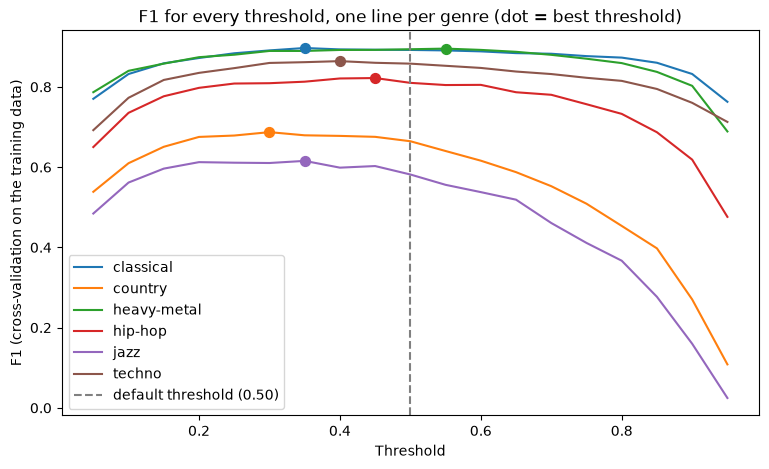

In [13]:
plt.figure(figsize=(9, 5))

# One line per genre: the F1 score for every threshold we tried
for genre_name, f1_scores in f1_per_threshold.items():
    line, = plt.plot(thresholds_to_try, f1_scores, label=genre_name)

    # A dot on the best threshold, in the same colour as the line
    plt.scatter(best_thresholds[genre_name], max(f1_scores), color=line.get_color(), s=50, zorder=3)

# The normal threshold, for comparison
plt.axvline(0.5, color='gray', linestyle='--', label='default threshold (0.50)')

plt.xlabel('Threshold')
plt.ylabel('F1 (cross-validation on the training data)')
plt.title('F1 for every threshold, one line per genre (dot = best threshold)')
plt.legend()
plt.show()

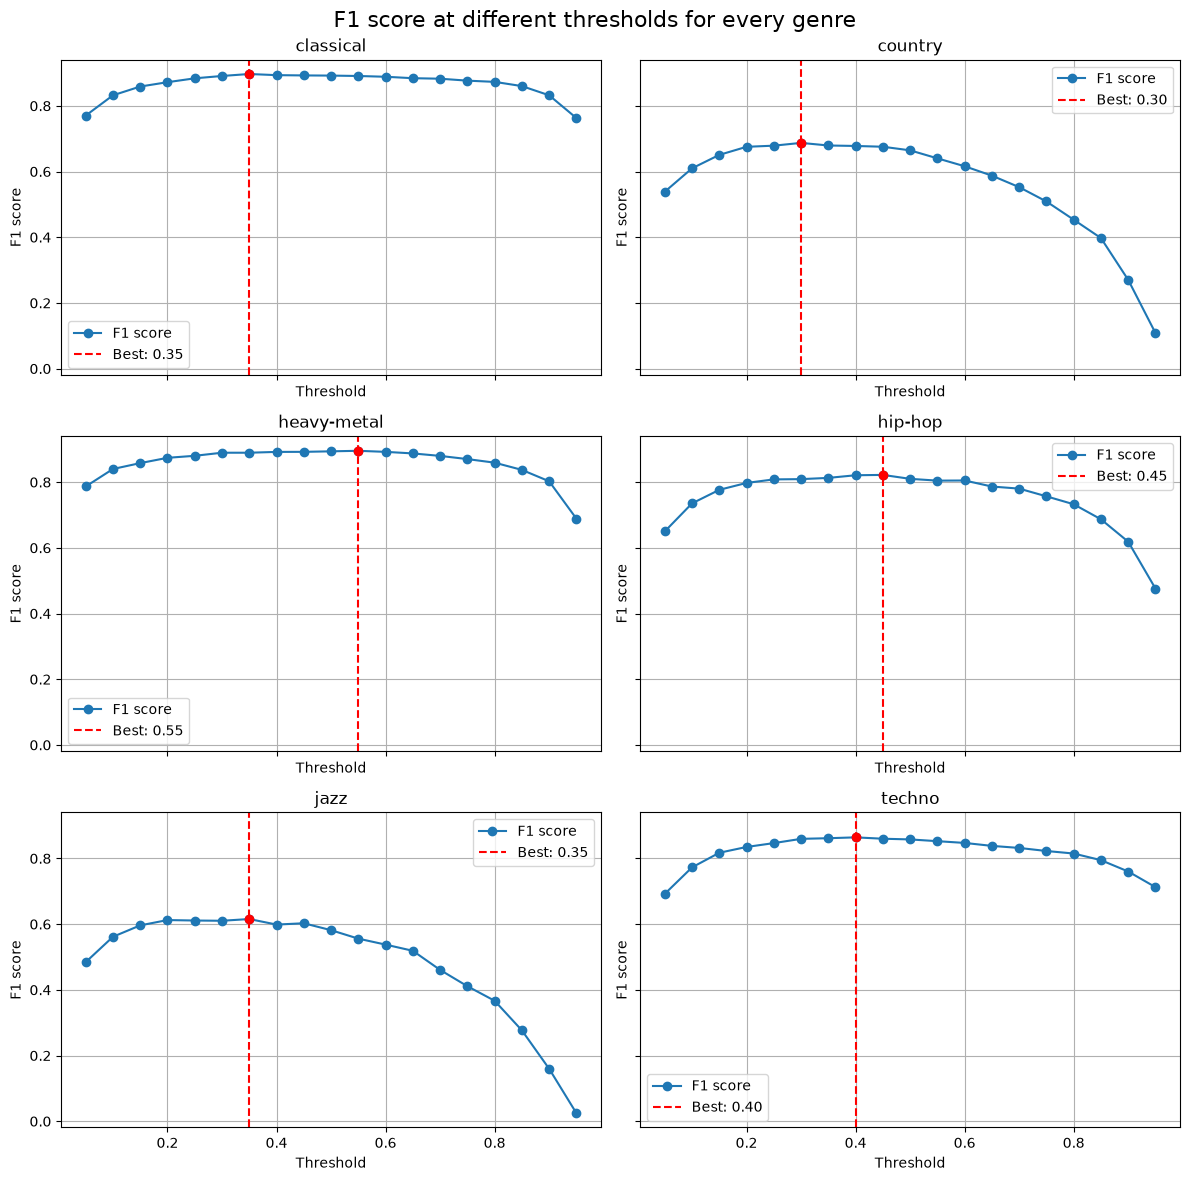

In [14]:

genres = list(label_encoder.classes_)

number_of_columns = 2
number_of_rows = (len(genres) + 1) // 2

fig, axes = plt.subplots(
    number_of_rows,
    number_of_columns,
    figsize=(12, 4 * number_of_rows),
    sharex=True,
    sharey=True
)

# Turn the 2D grid of axes into one simple list
axes = axes.flatten()

# Create one plot for each genre
for ax, genre_name in zip(axes, genres):

    scores = f1_per_threshold[genre_name]
    best_threshold = best_thresholds[genre_name]
    best_f1 = max(scores)

    # F1 score at every tested threshold
    ax.plot(
        thresholds_to_try,
        scores,
        marker="o",
        label="F1 score"
    )

    # Vertical line at the selected threshold
    ax.axvline(
        best_threshold,
        color="red",
        linestyle="--",
        label=f"Best: {best_threshold:.2f}"
    )

    # Red dot at the highest F1 score
    ax.scatter(
        best_threshold,
        best_f1,
        color="red",
        zorder=3
    )

    ax.set_title(genre_name)
    ax.set_xlabel("Threshold")
    ax.set_ylabel("F1 score")
    ax.grid()
    ax.legend()

# Hide unused plots if the number of genres is not even
for ax in axes[len(genres):]:
    ax.set_visible(False)

fig.suptitle("F1 score at different thresholds for every genre", fontsize=16)
fig.tight_layout()
plt.show()

In [15]:
# F1 at a few thresholds, so the numbers in the interpretation can be checked
for genre_name, f1_scores in f1_per_threshold.items():
    f1_at = dict(zip(thresholds_to_try, f1_scores))
    print(f"{genre_name:12} F1 at 0.20: {f1_at[0.20]:.3f}   0.30: {f1_at[0.30]:.3f}   0.35: {f1_at[0.35]:.3f}   "
          f"0.70: {f1_at[0.70]:.3f}   0.95: {f1_at[0.95]:.3f}")

classical    F1 at 0.20: 0.872   0.30: 0.891   0.35: 0.897   0.70: 0.883   0.95: 0.763
country      F1 at 0.20: 0.675   0.30: 0.687   0.35: 0.679   0.70: 0.553   0.95: 0.108
heavy-metal  F1 at 0.20: 0.874   0.30: 0.890   0.35: 0.890   0.70: 0.880   0.95: 0.689
hip-hop      F1 at 0.20: 0.798   0.30: 0.809   0.35: 0.813   0.70: 0.780   0.95: 0.476
jazz         F1 at 0.20: 0.612   0.30: 0.610   0.35: 0.616   0.70: 0.461   0.95: 0.025
techno       F1 at 0.20: 0.835   0.30: 0.860   0.35: 0.862   0.70: 0.832   0.95: 0.713


### Interpretation

Every curve has the same shape: low at both ends and highest somewhere in the middle. With a very low threshold like 0.05, the model says yes to almost every song that has even a small chance of being that genre, so it finds the real songs but also calls many other songs that genre (low precision). With a very high threshold like 0.95, it only says yes when it is almost completely sure, so it misses many of the real songs (low recall). F1 is highest where these two mistakes are balanced.

The genres the model is sure about have flat curves. From 0.20 to 0.70, heavy-metal stays between 0.874 and 0.895, and classical between 0.872 and 0.897. For these genres the exact threshold matters little.

Jazz and country have lower and steeper curves, with their tops to the left of 0.50. On the right side they fall fast: jazz goes from 0.616 at its best threshold to 0.461 at 0.70 and only 0.025 at 0.95, and country from 0.687 to 0.553 and 0.108. This fits the numbers above, where only 9% of the real jazz songs get a probability above 0.9. A high threshold therefore throws away almost all the jazz songs.

The tops of the curves are quite flat. For jazz, the F1 is almost the same at 0.20, 0.30 and 0.35 (0.612, 0.610 and 0.616). That means testing the thresholds in smaller steps, like 0.01, would only change the F1 by a tiny amount, and that difference would mostly be noise from the training data.

## Checking the thresholds on the test set

The thresholds were tuned on the training data, so now I check them on the test set, which the model has never seen. First I check every genre on its own as a yes/no question, in the same way as the tuning. Then I use the thresholds to give every song one genre, like the app will do. If several genres pass their threshold, the song gets the one with the highest probability. If no genre passes, the model answers "not sure" instead of guessing.

In [16]:
# The model's probabilities for the test songs
test_proba = model.predict_proba(test_features)

for genre_number, genre_name in enumerate(label_encoder.classes_):
    actual_genre = (test_targets == genre_number).to_numpy()
    genre_probabilities = test_proba[:, genre_number]

    f1_default = f1_score(actual_genre, genre_probabilities >= 0.50)
    f1_tuned = f1_score(actual_genre, genre_probabilities >= best_thresholds[genre_name])

    print(f"{genre_name}")
    print(f"  Tuned threshold: {best_thresholds[genre_name]:.2f}")
    print(f"  Test F1 at 0.50: {f1_default:.3f}")
    print(f"  Test F1 tuned:   {f1_tuned:.3f}")
    print(f"  Change:          {f1_tuned - f1_default:+.3f}")
    print()

classical
  Tuned threshold: 0.35
  Test F1 at 0.50: 0.895
  Test F1 tuned:   0.890
  Change:          -0.005

country
  Tuned threshold: 0.30
  Test F1 at 0.50: 0.712
  Test F1 tuned:   0.711
  Change:          -0.001

heavy-metal
  Tuned threshold: 0.55
  Test F1 at 0.50: 0.904
  Test F1 tuned:   0.894
  Change:          -0.010

hip-hop
  Tuned threshold: 0.45
  Test F1 at 0.50: 0.771
  Test F1 tuned:   0.780
  Change:          +0.009

jazz
  Tuned threshold: 0.35
  Test F1 at 0.50: 0.624
  Test F1 tuned:   0.650
  Change:          +0.026

techno
  Tuned threshold: 0.40
  Test F1 at 0.50: 0.832
  Test F1 tuned:   0.840
  Change:          +0.008



### Interpretation

On the test set, the tuned thresholds help three genres a little and make three slightly worse. Jazz gains the most, from an F1 of 0.624 to 0.650 (+0.026). That fits the training data, where jazz also gained the most (0.582 to 0.616). Hip-hop (+0.009) and techno (+0.008) gain a little, while heavy-metal (-0.010), classical (-0.005) and country (-0.001) get slightly worse.

Most of these changes are very small. The test set only has 100 jazz songs (20% of 500) and 127 country songs (633 minus the 506 in the training data), so a change of 0.01 is only one or two songs. Country is a good example: on the training data its threshold of 0.30 gave the second biggest gain (0.665 to 0.687), but on the test set it changes almost nothing. Jazz is the only genre where the gain is big enough to be fairly sure it is real.

In [17]:
def predict_with_thresholds(probabilities, thresholds):
    predictions = []

    for song_probabilities in probabilities:

        # The genres where the probability is at least that genre's threshold
        passed = [genre_number for genre_number in range(len(thresholds))
                  if song_probabilities[genre_number] >= thresholds[genre_number]]

        if len(passed) == 0:
            # No genre is sure enough
            predictions.append(-1)
        else:
            # Of the genres that passed, take the one with the highest probability
            best_genre = passed[np.argmax(song_probabilities[passed])]
            predictions.append(best_genre)

    return np.array(predictions)

In [18]:
# The thresholds as a list, in the same order as the genre numbers 0 to 5
threshold_list = [best_thresholds[genre_name] for genre_name in label_encoder.classes_]

threshold_pred = predict_with_thresholds(test_proba, threshold_list)
answered = threshold_pred != -1      # True for the songs that got a genre

print("Normal (highest probability):")
print(f"  Accuracy: {accuracy_score(test_targets, test_pred):.3f}")
print(f"  Macro F1: {f1_score(test_targets, test_pred, average='macro'):.3f}")
print()
print("With the tuned thresholds:")
print(f"  Not sure: {(~answered).sum()} of {len(test_targets)} songs")
print(f"  Accuracy on the songs that got a genre: {accuracy_score(test_targets[answered], threshold_pred[answered]):.3f}")
print(f"  Macro F1 on all songs (not sure counts as wrong): {f1_score(test_targets, threshold_pred, labels=range(6), average='macro'):.3f}")
print()

changed = answered & (threshold_pred != test_pred)
not_sure = ~answered
print(f"Songs that got a different genre than normal: {changed.sum()}")
print(f"Not sure songs the normal model got right anyway: {(test_pred[not_sure] == test_targets.to_numpy()[not_sure]).sum()} of {not_sure.sum()}")

Normal (highest probability):
  Accuracy: 0.817
  Macro F1: 0.797

With the tuned thresholds:
  Not sure: 37 of 930 songs
  Accuracy on the songs that got a genre: 0.829
  Macro F1 on all songs (not sure counts as wrong): 0.793

Songs that got a different genre than normal: 9
Not sure songs the normal model got right anyway: 17 of 37


### Interpretation

With the thresholds, 37 of the 930 test songs get "not sure", because none of the six genres reached its threshold. For the 893 songs that do get a genre, the accuracy is 0.829, a bit higher than the 0.817 of the normal model. If I count "not sure" as a wrong answer, the macro F1 is 0.793, a little lower than the 0.797 of the normal model. 9 songs got a different genre than with the normal rule. That happens when the most likely genre doesn't reach its threshold, but another genre with a low threshold, like country (0.30), does.

The "not sure" answer is a trade-off. The normal model would have been right on 17 of the 37 songs, so by saying "not sure" the model avoids 20 wrong answers, but it also holds back 17 right ones. Whether that is worth it depends on what the app is used for. If a wrong genre is worse than no answer, for example when songs are sorted into playlists automatically, "not sure" is better. If the user just wants a guess, the normal rule is better. I discuss this more in the ethics report, and in the app the user can change the thresholds themselves.

## Feature importance

The assignment asks for at least one feature importance method. I use two, so I can compare them.

Permutation importance shuffles one feature at a time on the test set and measures how much the macro F1 drops. A big drop means the model depends a lot on that feature. It works for any model and is measured on songs the model has never seen.

XGBoost's built-in importance measures how much every feature improved the trees during training. I use the total gain, which is the improvement added up over all the splits that use the feature. key and time_signature were one-hot encoded into several columns, so I add their columns together to get one number per original feature.

Sources:

- https://scikit-learn.org/stable/modules/permutation_importance.html
- https://scikit-learn.org/stable/modules/generated/sklearn.inspection.permutation_importance.html
- https://xgboost.readthedocs.io/en/stable/python/python_api.html#xgboost.Booster.get_score

In [19]:
# Shuffle one feature at a time on the test set and measure how much the macro F1 drops.
# Repeated 10 times per feature, since the shuffling is random.
result = permutation_importance(model, test_features, test_targets, scoring='f1_macro', n_repeats=10, random_state=random_state, n_jobs=-1)

permutation_df = pd.DataFrame({'importance': result.importances_mean, 'std': result.importances_std},
                              index=test_features.columns).sort_values('importance', ascending=False)
print(permutation_df.round(3))

                  importance    std
acousticness           0.203  0.013
danceability           0.116  0.008
instrumentalness       0.089  0.008
speechiness            0.054  0.006
energy                 0.053  0.007
duration_ms            0.042  0.008
valence                0.022  0.006
mode                   0.022  0.004
tempo                  0.022  0.007
loudness               0.018  0.007
key                    0.009  0.004
liveness               0.003  0.003
time_signature         0.002  0.001
explicit               0.002  0.002


In [20]:
# How much each column improved the trees in total during training ("total gain")
booster = model.named_steps['estimator'].get_booster()
total_gain = booster.get_score(importance_type='total_gain')     # {'f0': ..., 'f1': ..., ...}

# The columns after preprocessing, in the same order as f0, f1, f2, ...
column_names = model.named_steps['preprocess'].get_feature_names_out()

# Give every column its real name, for example f5 -> numeric__acousticness
gain_per_column = {}
for key, value in total_gain.items():
    column_number = int(key[1:])            # 'f5' -> 5
    gain_per_column[column_names[column_number]] = value
gain_per_column = pd.Series(gain_per_column)

# key and time_signature were one-hot encoded into several columns (key_0, key_1, ...).
# I add those columns together, so every original feature gets one number.
def original_feature(column_name):
    part, feature = column_name.split('__')         # 'categorical__key_5' -> 'categorical', 'key_5'
    if part == 'categorical':
        feature = feature.rsplit('_', 1)[0]         # 'key_5' -> 'key'
    return feature

builtin_importance = gain_per_column.groupby(original_feature).sum()

# As a share of the total, so all the features add up to 1
builtin_importance = (builtin_importance / builtin_importance.sum()).sort_values(ascending=False)
print(builtin_importance.round(3))

acousticness        0.243
danceability        0.137
instrumentalness    0.114
energy              0.094
speechiness         0.084
loudness            0.082
duration_ms         0.075
tempo               0.057
valence             0.048
liveness            0.029
mode                0.017
key                 0.012
explicit            0.006
time_signature      0.003
dtype: float64


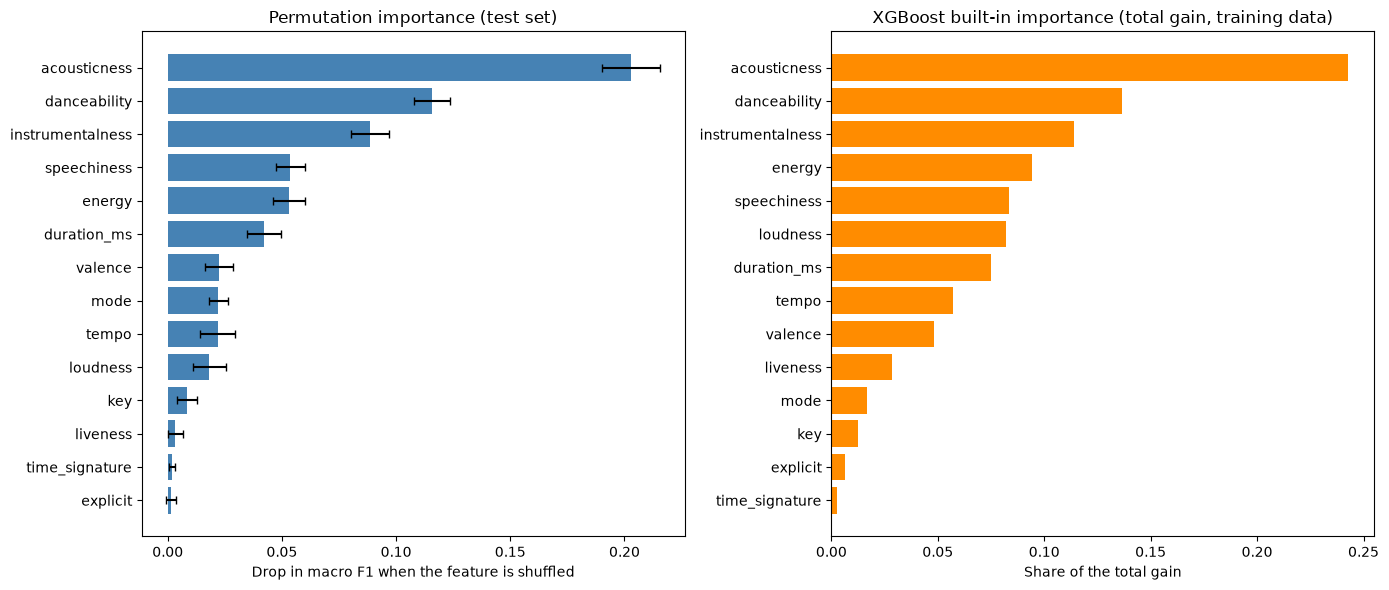

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Left: permutation importance on the test set, with the spread over the 10 shuffles
permutation_sorted = permutation_df.sort_values('importance')
axes[0].barh(permutation_sorted.index, permutation_sorted['importance'],
             xerr=permutation_sorted['std'], color='steelblue', capsize=3)
axes[0].set_title('Permutation importance (test set)')
axes[0].set_xlabel('Drop in macro F1 when the feature is shuffled')

# Right: XGBoost's own importance, measured during training
builtin_sorted = builtin_importance.sort_values()
axes[1].barh(builtin_sorted.index, builtin_sorted.values, color='darkorange')
axes[1].set_title('XGBoost built-in importance (total gain, training data)')
axes[1].set_xlabel('Share of the total gain')

fig.tight_layout()
plt.show()

In [22]:
# Both methods next to each other, with the rank of every feature (1 = most important)
comparison = pd.DataFrame({
    'permutation': permutation_df['importance'],
    'total gain': builtin_importance,
})
comparison['rank permutation'] = comparison['permutation'].rank(ascending=False).astype(int)
comparison['rank total gain'] = comparison['total gain'].rank(ascending=False).astype(int)

print(comparison.sort_values('rank permutation').round(3))

                  permutation  total gain  rank permutation  rank total gain
acousticness            0.203       0.243                 1                1
danceability            0.116       0.137                 2                2
instrumentalness        0.089       0.114                 3                3
speechiness             0.054       0.084                 4                5
energy                  0.053       0.094                 5                4
duration_ms             0.042       0.075                 6                7
valence                 0.022       0.048                 7                9
mode                    0.022       0.017                 8               11
tempo                   0.022       0.057                 9                8
loudness                0.018       0.082                10                6
key                     0.009       0.012                11               12
liveness                0.003       0.029                12               10

### Interpretation

Both methods agree on what matters most. The top three are the same, in the same order: acousticness, danceability and instrumentalness. They also agree on what matters least: time_signature and explicit are at the bottom of both, together with key and liveness.

Permutation importance says that acousticness is by far the most important feature. When it is shuffled, the macro F1 on the test set drops by 0.203, from 0.797 to about 0.59. Then come danceability (0.116), instrumentalness (0.089), speechiness (0.054) and energy (0.053). This fits the EDA in my previous assignment, where acousticness and instrumentalness separated the calm genres (classical and jazz) from the rest, danceability separated hip-hop and techno from the others, and speechiness mostly helped to recognise hip-hop. The black lines in the plot are short for every feature, so the order is the same no matter how the songs are shuffled.

In the built-in importance, acousticness is also first with 24.3% of the total gain, followed by danceability (13.7%) and instrumentalness (11.4%). The biggest difference between the two methods is loudness. It is number 6 in the total gain, but only number 10 in the permutation importance (0.018). In my previous assignment I found that loudness is strongly correlated with energy (0.82). The trees use loudness a lot during training, but when it is shuffled on the test set, the model can get almost the same information from energy, so the score hardly drops. Total gain gives credit to every feature the trees used while learning, while permutation importance only shows what the model really needs to be right on new songs. That is why I trust permutation importance more, and why it is the main method in the app.

Popularity is not in the list any more. In my previous assignment it was the most important feature (0.220), even though it says nothing about how a song sounds. Without it, the model has to rely on the sound, and acousticness takes over the top spot. The model is a bit worse (macro F1 0.797 instead of 0.863), but its decisions are now based on how a song sounds, and a song from a small, unknown artist is no longer pushed towards jazz, country or classical just because few people listen to it.

## Saving the results for the app

The model is already saved with pickle. Here I save everything else the backend needs, so it doesn't have to calculate anything heavy itself. I use JSON and CSV for these files, because they are plain text that can be opened and checked, and unlike pickle they can't run any code when they are loaded.

- thresholds.json: the tuned threshold for every genre. The app starts with these, and the user can change them.
- test_probabilities.csv: the probabilities for every test song and its real genre. With these, the backend can calculate all the test results again for any thresholds the user picks, without using the model.
- threshold_curves.csv: the F1 for every threshold and genre, for the threshold plot in the app.
- feature_importance.csv: both feature importance methods.
- songs.csv: all 4,650 songs with their names, features and genre, so the user can search for a song. It also says if a song was in the training or the test set.

Sources:

- https://docs.python.org/3/library/json.html
- https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.to_csv.html

In [23]:
with open('models/thresholds.json', 'w') as f:
    json.dump(best_thresholds, f, indent=2)

In [24]:
test_results = pd.DataFrame(test_proba, columns=label_encoder.classes_, index=test_features.index)
test_results.insert(0, 'true_genre', label_encoder.inverse_transform(test_targets))
test_results.index.name = 'song_id'
test_results.to_csv('models/test_probabilities.csv')

In [25]:
threshold_curves = pd.DataFrame(f1_per_threshold, index=thresholds_to_try)
threshold_curves.index.name = 'threshold'
threshold_curves.to_csv('models/threshold_curves.csv')

In [26]:
feature_importance = pd.DataFrame({
    'permutation': permutation_df['importance'],
    'permutation_std': permutation_df['std'],
    'total_gain': builtin_importance,
}).sort_values('permutation', ascending=False)
feature_importance.index.name = 'feature'
feature_importance.to_csv('models/feature_importance.csv')

In [27]:
# Names + features + genre for every song, with the same index (song_id) as the test file
songs = song_info.join(features)
songs['genre'] = df['track_genre']

# Mark which songs the model was trained on, so the app can warn about them
songs['set'] = 'train'
songs.loc[test_indices, 'set'] = 'test'

songs.index.name = 'song_id'
songs.to_csv('models/songs.csv')

In [28]:
for file_name in sorted(os.listdir('models')):
    size_kb = os.path.getsize(f'models/{file_name}') / 1024
    print(f"{file_name:25} {size_kb:8.1f} KB")

feature_importance.csv         1.0 KB
genre_model.pkl             3543.5 KB
songs.csv                    837.4 KB
test_probabilities.csv        78.8 KB
threshold_curves.csv           2.2 KB
thresholds.json                0.1 KB
